##### Introduction

In this laboratory v3 we are going to make use of a Logistic Regression Model, note that we no longer use Glucose as our target value, instead, we are 
using it as a new feature with skin thickness, insulin, preganancies and diabetes pedigree function.

Our new target value is Outcome wich denotes if a patient is 1 = diabetic, or 0 = not diabetic

In [43]:
import copy, math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the diabetes dataset
dt = pd.read_csv('diabetes.csv')

# Before cleaning the dataset, print the shape and types of the original DataFrame
X_train = dt[['BMI', 'Age', 'BloodPressure', 'Insulin', 'SkinThickness', 'Pregnancies', 'DiabetesPedigreeFunction', 'Glucose']].to_numpy()
y_train = dt['Outcome'].to_numpy()
print(f"X Shape before cleaning: {X_train.shape}, X Type before cleaning:{type(X_train)})")
print(f"y Shape before cleaning: {y_train.shape}, y Type before cleaning:{type(y_train)})")

# Clean the dataset by removing rows with zero values in the specified columns
# Pregnancies and DiabetesPedigreeFunction can have zero values, so we don't filter them out
df_clean = dt[(dt['BMI'] != 0) & (dt['Glucose'] != 0) & (dt['Age'] != 0) & (dt['BloodPressure'] != 0) & (dt['Insulin'] != 0) & (dt['SkinThickness'] != 0)]

# Transform the cleaned DataFrame into NumPy arrays for features and target variable
X_train = df_clean[['BMI', 'Age', 'BloodPressure', 'Insulin', 'SkinThickness', 'Pregnancies', 'DiabetesPedigreeFunction', 'Glucose']].to_numpy()
y_train = df_clean['Outcome'].to_numpy()

# Print the shapes and types of the feature and target arrays
print(f"X Shape after cleaning: {X_train.shape}, X Type:{type(X_train)})")
print(f"y Shape after cleaning: {y_train.shape}, y Type:{type(y_train)})")

# We lost almost half of the data after cleaning because of Insulin and SkinThickness having a lot of zero values

X Shape before cleaning: (768, 8), X Type before cleaning:<class 'numpy.ndarray'>)
y Shape before cleaning: (768,), y Type before cleaning:<class 'numpy.ndarray'>)
X Shape after cleaning: (392, 8), X Type:<class 'numpy.ndarray'>)
y Shape after cleaning: (392,), y Type:<class 'numpy.ndarray'>)


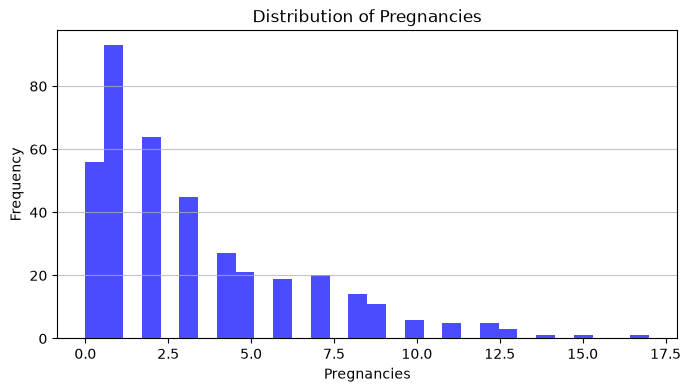

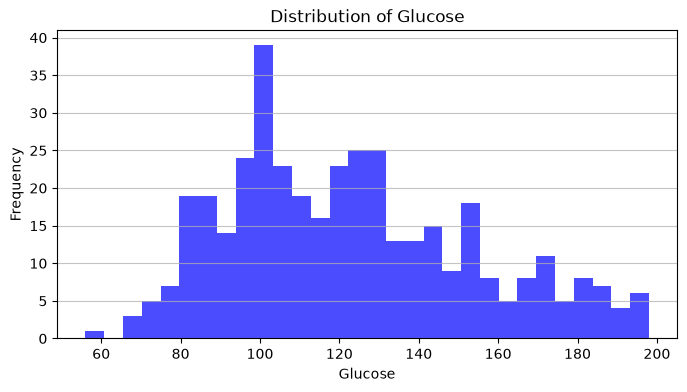

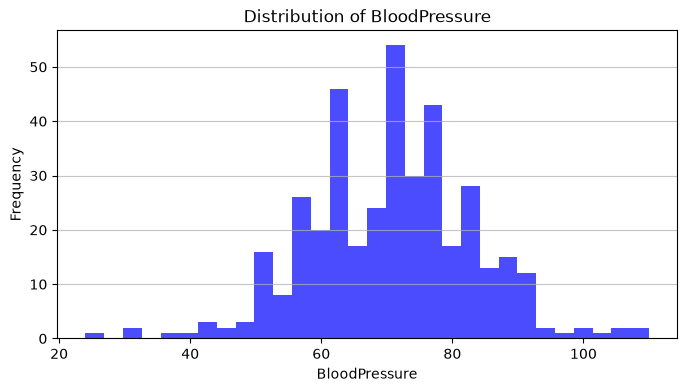

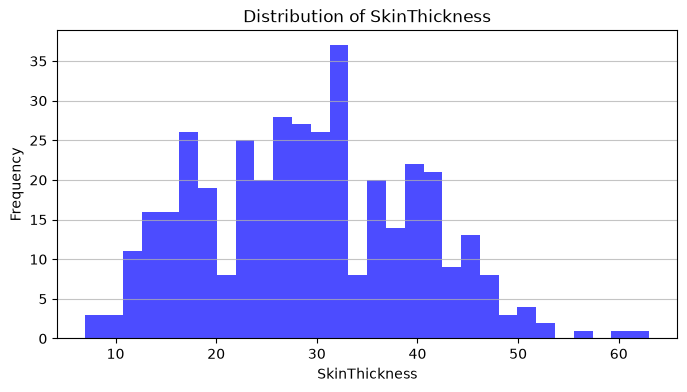

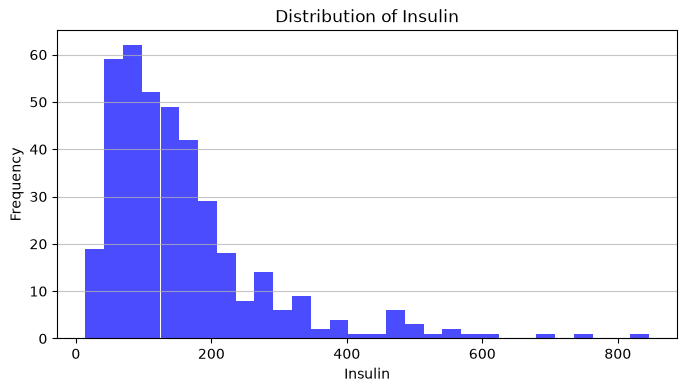

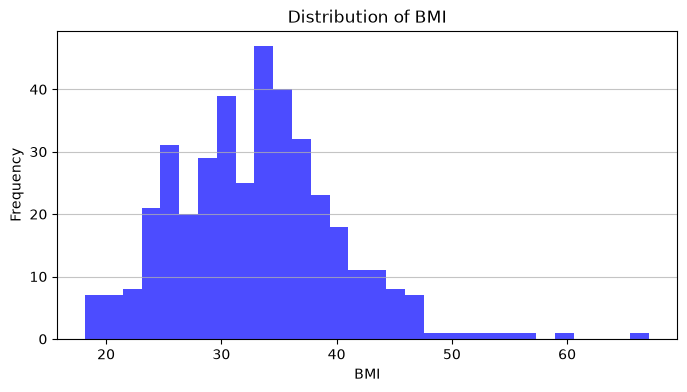

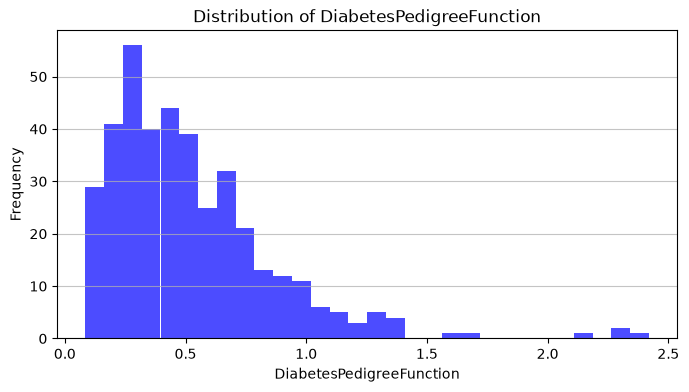

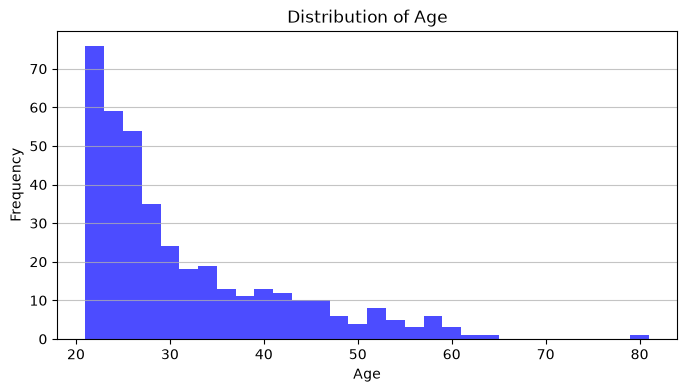

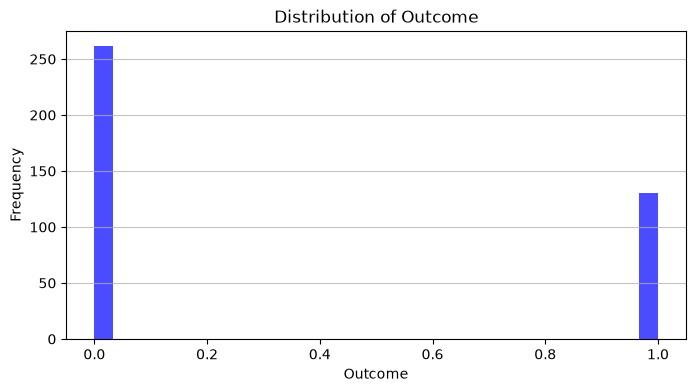

In [44]:
# Plot the distribution of the features to see if we can identify any patterns or outliers

for col in df_clean.columns:
    plt.figure(figsize=(8, 4))
    plt.hist(df_clean[col], bins=30, alpha=0.7, color='blue')
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.grid(axis='y', alpha=0.75)
    plt.show()

Before normalization:
[[ 28.1    21.     66.    ...   1.      0.167  89.   ]
 [ 43.1    33.     40.    ...   0.      2.288 137.   ]
 [ 31.     26.     50.    ...   3.      0.248  78.   ]
 ...
 [ 28.4    22.     58.    ...   2.      0.766  88.   ]
 [ 32.9    63.     76.    ...  10.      0.171 101.   ]
 [ 26.2    30.     72.    ...   5.      0.245 121.   ]]
After normalization:
[[-0.710421   -0.9682991  -0.37365481 ... -0.7174265  -1.03187632
  -1.09104581]
 [ 1.42673006  0.2095853  -2.45696436 ... -1.02921274  5.11511079
   0.46631407]
 [-0.29723846 -0.47751393 -1.65569146 ... -0.09385402 -0.79712575
  -1.44794079]
 ...
 [-0.66767798 -0.87014206 -1.01467313 ... -0.40564026  0.70411863
  -1.12349081]
 [-0.02653266  3.15429628  0.42761809 ...  2.08864966 -1.0202837
  -0.70170584]
 [-0.9811268  -0.0848858   0.10710893 ...  0.52971846 -0.80582021
  -0.05280589]]


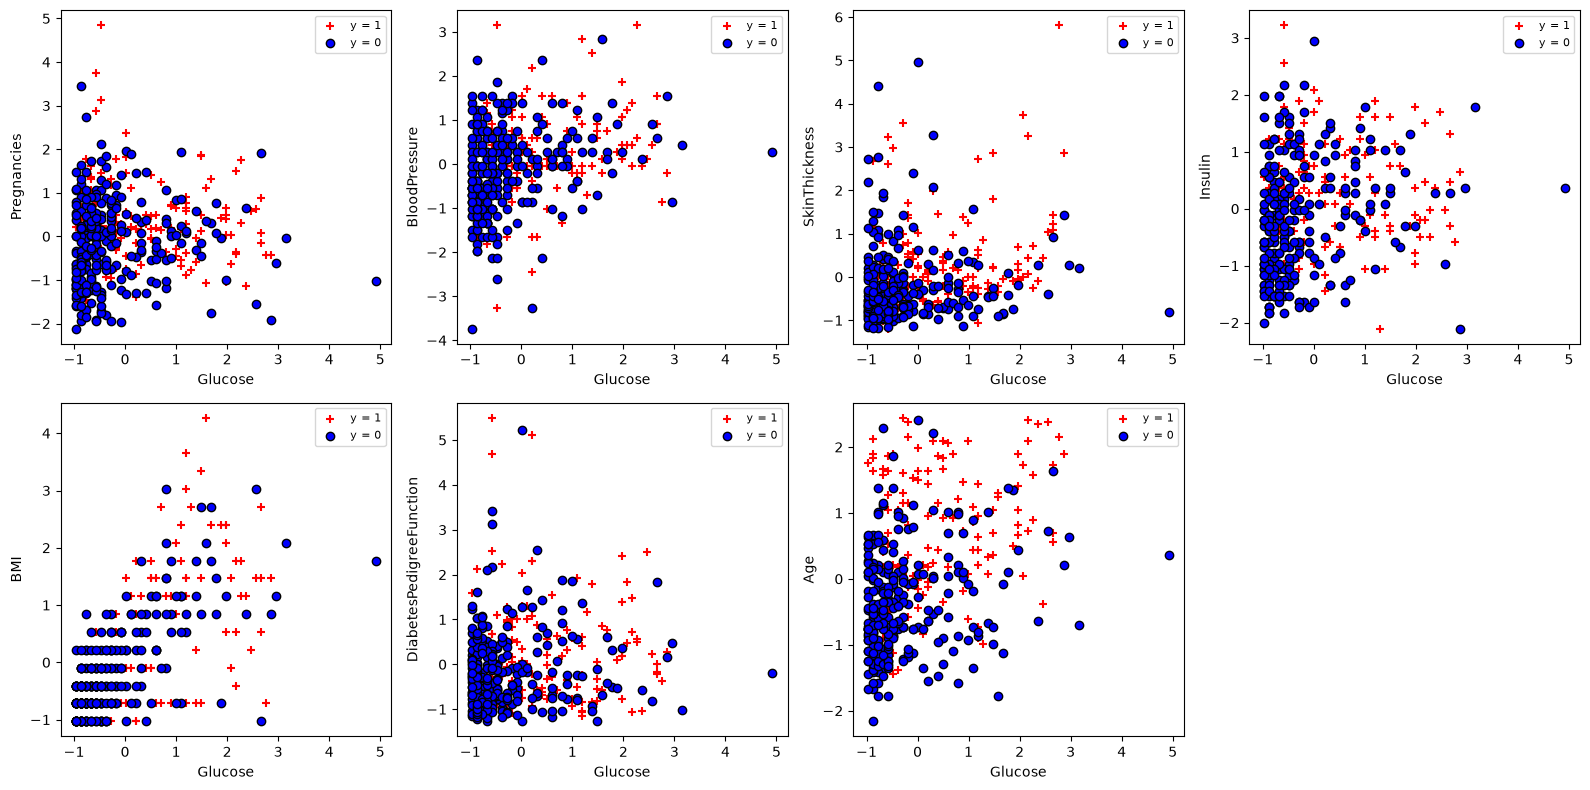

In [45]:
# The cleaned dataset has a uniform distribution of values across the features and also lacks of outliers, this should help the model to generalize better and avoid overfitting

# Before ploting our features, normalize them with z-score normalization
def zscore_normalize_features(X):
    """
    Normalize the features using z-score normalization.
    
    Parameters:
    X (numpy.ndarray): The input feature array.
    
    Returns:
    numpy.ndarray: The normalized feature array.
    """
    mean = np.mean(X, axis=0)
    std = np.std(X, axis=0)
    
    X_norm = (X - mean) / std if std.any() else X - mean
    
    return X_norm, mean, std

print("Before normalization:")
print(X_train)

X_train_norm, mean, std = zscore_normalize_features(X_train)

print("After normalization:")
print(X_train_norm)


# Plot our 8 features against each other to see if we can identify any patterns or relationships between them

features = ['Pregnancies','Glucose','BloodPressure','SkinThickness',
            'Insulin','BMI','DiabetesPedigreeFunction','Age']
g = features.index('Glucose')
pairs = [f for f in features if f != 'Glucose']
fig, ax = plt.subplots(2, 4, figsize=(16, 8))
for k, f in enumerate(pairs):
    j = features.index(f); a = ax[k // 4, k % 4]
    a.scatter(X_train_norm[y_train==1, g], X_train_norm[y_train==1, j], c='r', marker='+', label='y = 1')
    a.scatter(X_train_norm[y_train==0, g], X_train_norm[y_train==0, j], c='b', marker='o', edgecolors='k', label='y = 0')
    a.set_xlabel('Glucose'); a.set_ylabel(f); a.legend(fontsize=8)
ax[1, 3].axis('off')
plt.tight_layout(); plt.show()

In [46]:
def compute_cost_reg_logistic(X, y, w, b, lam):
    """
    J logistic = (1/m) * sum( -y[i] * log(f) - (1 - y[i]) * log(1 - f) ) + (lam/(2*m)) * sum(w[j]^2)
    where f = 1 / (1 + exp(-(X[i] * w + b)))
    """
    m, n = X.shape
    cost = 0.0
    for i in range(m):
        f = 1 / (1 + np.exp(-(np.dot(X[i], w) + b)))
        cost = cost + (-(y[i] * np.log(f) + (1 - y[i]) * np.log(1 - f)))

    j_plain = cost / m
    penalize = 0.0

    for j in range(n):
        penalize = penalize + w[j] ** 2
    penalize = (lam / (2 * m)) * penalize

    total_cost = j_plain + penalize
    return total_cost

In [47]:
def compute_gradient_reg_logistic(X, y, w, b, lam):
    """
    Gradient of the cost function for regularized logistic regression.
    """
    m, n = X.shape
    dj_dw = np.zeros(n)
    dj_db = 0.0
    for i in range(m):
        err = 1 / (1 + np.exp(-(np.dot(X[i], w) + b))) - y[i]
        for j in range(n):
            dj_dw[j] = dj_dw[j] + err * X[i, j]
        dj_db = dj_db + err

    for j in range(n):
        dj_dw[j] = dj_dw[j] / m + (lam / m) * w[j]
        
    return dj_dw, dj_db / m

In [48]:
def gradient_descent(X, y, w_in, b_in, alpha, num_iters, lam):
    """
    Performs batch gradient descent to learn w and b. Updates w and b by taking num_iters gradient steps with learning rate alpha.

    Args:
        X (ndarray): The input feature array.
        y (ndarray): The target variable array.
        w_in (ndarray): Initial weights.
        b_in (float): Initial bias.
        alpha (float): Learning rate.
        num_iters (int): Number of iterations for gradient descent.
        lam (float): Regularization parameter.

        Returns:
        w (ndarray): Updated weights after gradient descent.
        b (float): Updated bias after gradient descent.
        J_history (list): History of cost function values during gradient descent.
    """
    w = copy.deepcopy(w_in)
    b = b_in
    J_history = []

    for i in range(num_iters):
        dj_dw, dj_db = compute_gradient_reg_logistic(X, y, w, b, lam)
        w = w - alpha * dj_dw
        b = b - alpha * dj_db

        if i < 100000:  # prevent resource exhaustion
            J_history.append(compute_cost_reg_logistic(X, y, w, b, lam))

        if i % math.ceil(num_iters / 10) == 0:
            print(f"Iteration {i:4d}: Cost {J_history[-1]:8.3f}, weights: {w}, bias: {b}")

    return w, b, J_history

Iteration    0: Cost    0.674, weights: [0.01271717 0.01651584 0.00907105 0.01419128 0.01204945 0.01207912
 0.00985523 0.02427927], bias: -0.01683673469387755
Iteration  100: Cost    0.451, weights: [0.28298403 0.31777535 0.0766673  0.16041639 0.18299434 0.21888924
 0.29439152 0.75740756], bias: -0.7405738502900395
Iteration  200: Cost    0.442, weights: [0.35613661 0.33515475 0.03942446 0.06154445 0.17562892 0.23503615
 0.34987809 0.95569761], bias: -0.9065021565793443
Iteration  300: Cost    0.440, weights: [ 0.40296077  0.33990942  0.01760584 -0.00435107  0.16342491  0.2450353
  0.37042634  1.05394152], bias: -0.9593336952159459
Iteration  400: Cost    0.439, weights: [ 0.43360393  0.34173234  0.00435902 -0.04290524  0.15173777  0.25153443
  0.38001023  1.10683621], bias: -0.9797653693006895
Iteration  500: Cost    0.439, weights: [ 0.45380081  0.34269683 -0.00373433 -0.06502553  0.14221999  0.25573399
  0.38511048  1.13618077], bias: -0.9889362685532873
Iteration  600: Cost    0.43

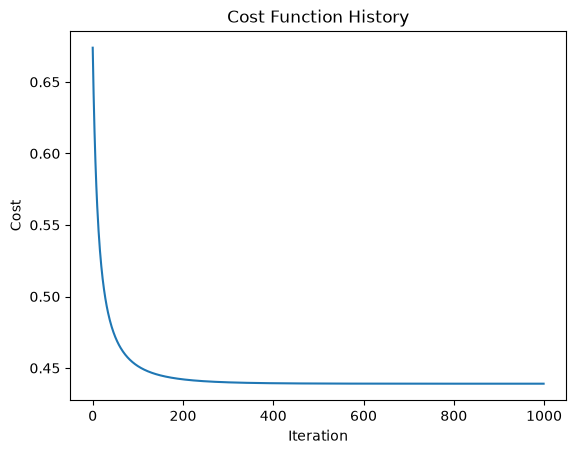

In [143]:
# Test the gradient descent function with a small number of iterations and a small learning rate
initial_w = np.zeros(X_train_norm.shape[1])
initial_b = 0.0
learning_rate = 0.1 # 0.01 was small
num_iterations = 1000 # we get to the lowest cost in 1000 iterations
lambda_param = 0.1  # We got better results with a small value, we have to see if it overfits or not

"""
Lambda | Cost
0 = 0.439
0.1 = 0.439 
1 = 0.441
10 = 0.459
"""

w, b, J_history = gradient_descent(X_train_norm, y_train, initial_w, initial_b, learning_rate, num_iterations, lambda_param)

# Plot the cost function history to visualize convergence
plt.plot(J_history)
plt.xlabel("Iteration")
plt.ylabel("Cost")
plt.title("Cost Function History")
plt.show()

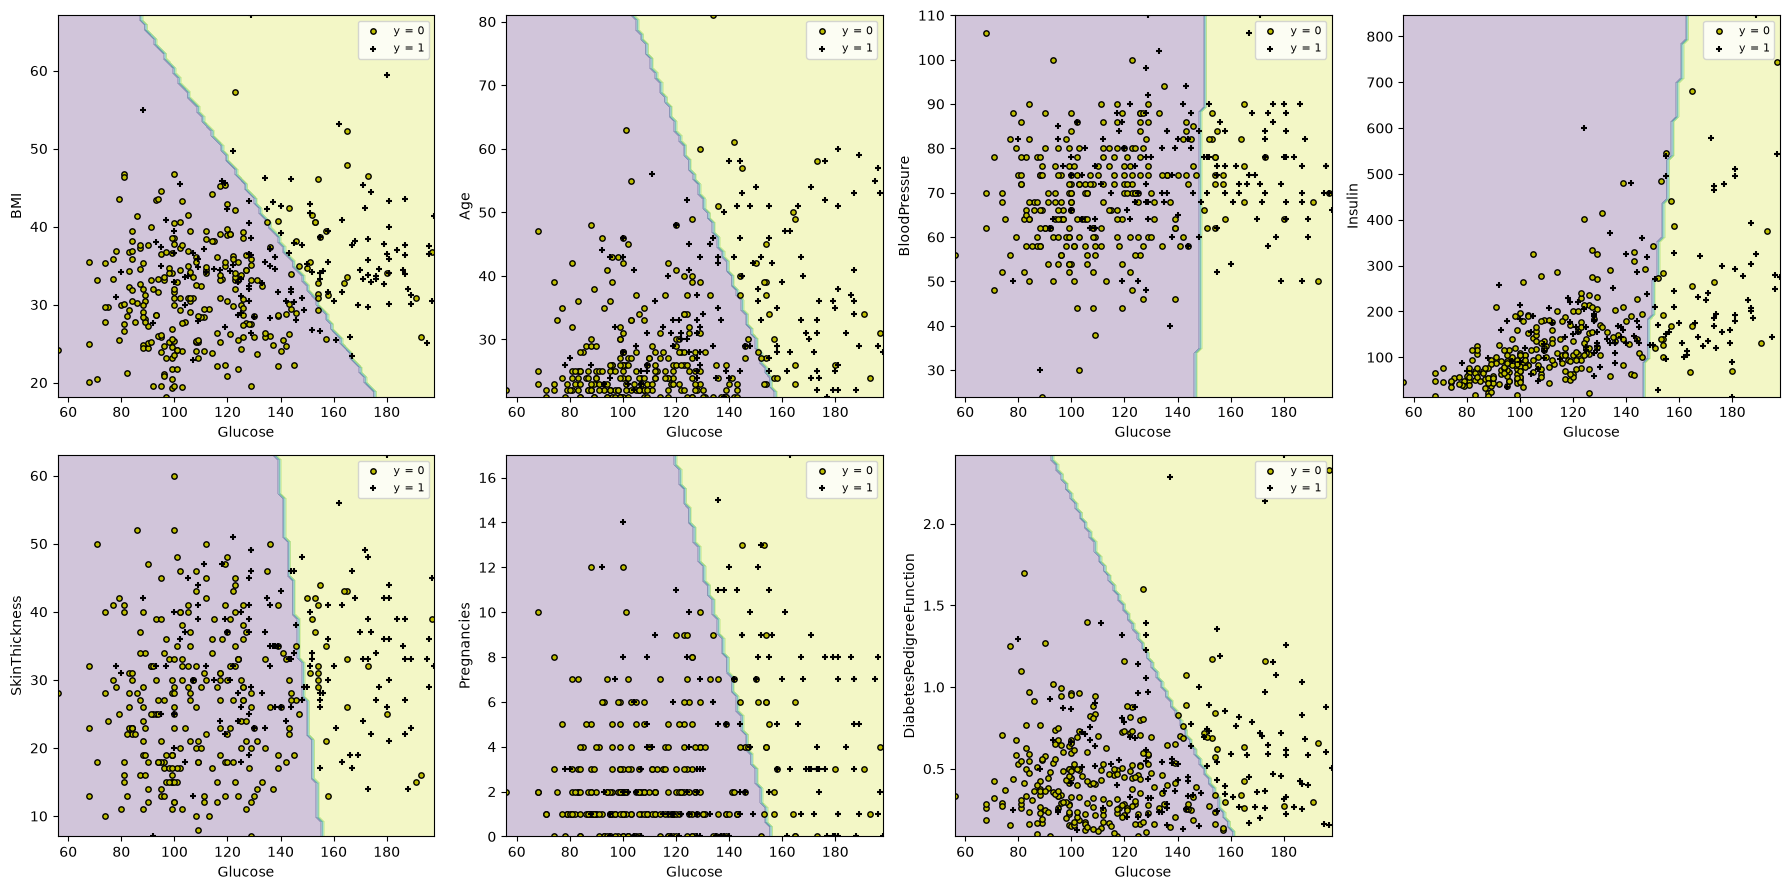

In [56]:
# Plot the decision boundary for our logistic regression model

features = ['BMI','Age','BloodPressure','Insulin','SkinThickness',
            'Pregnancies','DiabetesPedigreeFunction','Glucose']
g = features.index('Glucose')
pairs = [f for f in features if f != 'Glucose']
fig, ax = plt.subplots(2, 4, figsize=(18, 9))
for k, f in enumerate(pairs):
    j = features.index(f); a = ax[k // 4, k % 4]
    # rejilla 2D en unidades originales
    gx = np.linspace(X_train[:, g].min(), X_train[:, g].max(), 80)
    fy = np.linspace(X_train[:, j].min(), X_train[:, j].max(), 80)
    xx, yy = np.meshgrid(gx, fy)
    grid = np.tile(X_train.mean(axis=0), (80*80, 1))
    grid[:, g], grid[:, j] = xx.ravel(), yy.ravel()
    grid_n = (grid - mean) / std
    pz = (1/(1+np.exp(-(grid_n @ w + b))) >= 0.5).astype(int).reshape(80, 80)
    a.contourf(xx, yy, pz, alpha=0.25)
    a.scatter(X_train[y_train==0, g], X_train[y_train==0, j], c='y', marker='o', edgecolors='k', s=15, label='y = 0')
    a.scatter(X_train[y_train==1, g], X_train[y_train==1, j], c='k', marker='+', s=25, label='y = 1')
    a.set_xlabel('Glucose'); a.set_ylabel(f); a.legend(fontsize=8)
ax[1, 3].axis('off')
plt.tight_layout(); plt.show()

In [172]:
# We can see that the decision boundary is far from perfect because of the overlapping data

# Organize our features by their importance based on the absolute values of the weights learned by the model
feature_importance = pd.DataFrame({'Feature': features, 'Weight': w})
feature_importance['Importance'] = feature_importance['Weight'].abs()
feature_importance = feature_importance.sort_values(by='Importance', ascending=False)

print("Feature Importance based on learned weights:")
print(feature_importance)

Feature Importance based on learned weights:
                    Feature    Weight  Importance
7                   Glucose  1.172661    1.172661
0                       BMI  0.488031    0.488031
6  DiabetesPedigreeFunction  0.391830    0.391830
1                       Age  0.344803    0.344803
5               Pregnancies  0.262327    0.262327
4             SkinThickness  0.122083    0.122083
3                   Insulin -0.093434    0.093434
2             BloodPressure -0.015535    0.015535


In [170]:
# We could´nt lower the cost because data overlaps too much, even if we move the decision boundary, we will always have a lot of misclassified points

# Let`s test our model with new data points to see if it can predict the outcome correctly

def predict(X, w, b):
    """
    Predicts the outcome for given input features using the learned weights and bias.

    Args:
        X (ndarray): The input feature array.
        w (ndarray): Learned weights.
        b (float): Learned bias.

    Returns:
      p : (ndarray (m,)) The predictions for X using a threshold at 0.5
    """

    m, n = X.shape   
    p = np.zeros(m)
   
    for i in range(m):   
        f_wb = 1 / (1 + np.exp(-(np.dot(X[i], w) + b)))
        # Apply the threshold
        p[i] = f_wb >= 0.5

    return p

# Test the predict function with new data points
# Features: BMI, Age, BloodPressure, Insulin, SkinThickness, Pregnancies, DiabetesPedigreeFunction, Glucose
test1 = np.array([
    [27.5, 21, 80, 20, 30, 1, 0.5, 100], 
    [27.5, 21, 80, 20, 30, 1, 0.5, 160],   
    [27.5, 21, 80, 20, 30, 1, 0.5, 170],  
    [27.5, 21, 80, 20, 30, 1, 0.5, 180],    
])
test1_norm = (test1 - mean) / std

predictions = predict(test1_norm, w, b)

print("Predictions for new data points (testing glucose):", predictions," (0 = No Diabetes, 1 = Diabetes)")


test2 = np.array([
    [27.5, 21, 80, 20, 30, 1, 0.5, 130], 
    [35, 21, 80, 20, 30, 1, 0.5, 130],   
    [40, 21, 80, 20, 30, 1, 0.5, 130],  
    [50, 21, 80, 20, 30, 1, 0.5, 130],    
])
test2_norm = (test2 - mean) / std

predictions = predict(test2_norm, w, b)

print("Predictions for new data points (testing BMI):", predictions," (0 = No Diabetes, 1 = Diabetes)")


test3 = np.array([
    [35, 21, 80, 20, 30, 1, 0.5, 130], 
    [35, 35, 80, 20, 30, 1, 0.5, 130],   
    [35, 45, 80, 20, 30, 1, 0.5, 130],  
    [35, 60, 80, 20, 30, 1, 0.5, 130],    
])
test3_norm = (test3 - mean) / std

predictions = predict(test3_norm, w, b)

print("Predictions for new data points (testing age):", predictions," (0 = No Diabetes, 1 = Diabetes)")


test4 = np.array([
    [35, 50, 80, 20, 30, 0, 0.5, 130], 
    [35, 50, 80, 20, 30, 1, 0.5, 130],   
    [35, 50, 80, 20, 30, 2, 0.5, 130],  
    [35, 50, 80, 20, 30, 3, 0.5, 130],    
])
test4_norm = (test4 - mean) / std

predictions = predict(test4_norm, w, b)

print("Predictions for new data points (testing pregnancies):", predictions," (0 = No Diabetes, 1 = Diabetes)")


test5 = np.array([
    [35, 50, 100, 25, 30, 1, 0.5, 130], 
    [35, 50, 120, 25, 30, 1, 0.5, 130],   
    [35, 50, 140, 25, 30, 1, 0.5, 130],  
    [35, 50, 190, 25, 30, 1, 0.5, 130],    
])
test5_norm = (test5 - mean) / std

predictions = predict(test5_norm, w, b)

print("Predictions for new data points (testing blood pressure):", predictions," (0 = No Diabetes, 1 = Diabetes)")


test6 = np.array([
    [35, 50, 140, 25, 30, 1, 0.5, 130], 
    [35, 50, 140, 40, 30, 1, 0.5, 130],   
    [35, 50, 140, 60, 30, 1, 0.5, 130],  
    [35, 50, 140, 100, 30, 1, 0.5, 130],    
])
test6_norm = (test6 - mean) / std

predictions = predict(test6_norm, w, b)

print("Predictions for new data points (testing insulin):", predictions," (0 = No Diabetes, 1 = Diabetes)")



test7 = np.array([
    [35, 50, 140, 40, 30, 1, 0.5, 130], 
    [35, 50, 140, 40, 35, 1, 0.5, 130],   
    [35, 50, 140, 40, 40, 1, 0.5, 130],  
    [35, 50, 140, 40, 45, 1, 0.5, 130],    
])
test7_norm = (test7 - mean) / std

predictions = predict(test7_norm, w, b)

print("Predictions for new data points (testing skin thickness):", predictions," (0 = No Diabetes, 1 = Diabetes)")


test8 = np.array([
    [35, 50, 140, 40, 40, 1, 0.3, 130], 
    [35, 50, 140, 40, 40, 1, 0.4, 130],   
    [35, 50, 140, 40, 40, 1, 0.5, 130],  
    [35, 50, 140, 40, 40, 1, 0.6, 130],    
])
test8_norm = (test8 - mean) / std

predictions = predict(test8_norm, w, b)

print("Predictions for new data points (testing diabetes pedigree function):", predictions," (0 = No Diabetes, 1 = Diabetes)")


final_test = np.array([
    [35, 50, 140, 40, 40, 1, 0.5, 130],  
])
final_test_norm = (final_test - mean) / std

predictions = predict(final_test_norm, w, b)

print("Predictions for new data points (testing all limits found):", predictions," (0 = No Diabetes, 1 = Diabetes)")

Predictions for new data points (testing glucose): [0. 0. 0. 1.]  (0 = No Diabetes, 1 = Diabetes)
Predictions for new data points (testing BMI): [0. 0. 0. 1.]  (0 = No Diabetes, 1 = Diabetes)
Predictions for new data points (testing age): [0. 0. 0. 1.]  (0 = No Diabetes, 1 = Diabetes)
Predictions for new data points (testing pregnancies): [0. 0. 1. 1.]  (0 = No Diabetes, 1 = Diabetes)
Predictions for new data points (testing blood pressure): [0. 0. 0. 0.]  (0 = No Diabetes, 1 = Diabetes)
Predictions for new data points (testing insulin): [0. 0. 0. 0.]  (0 = No Diabetes, 1 = Diabetes)
Predictions for new data points (testing skin thickness): [0. 0. 0. 1.]  (0 = No Diabetes, 1 = Diabetes)
Predictions for new data points (testing diabetes pedigree function): [0. 0. 0. 1.]  (0 = No Diabetes, 1 = Diabetes)
Predictions for new data points (testing all limits found): [0.]  (0 = No Diabetes, 1 = Diabetes)
